# Sleep Health & Lifestyle Analysis  
### Using Data Cleaning, EDA, and K-Means Clustering

This capstone project analyzes how lifestyle and health factors such as stress, physical activity, BMI, heart rate, blood pressure, and sleep habits relate to sleep quality and sleep disorders.

The goal is to:

- Understand correlations between lifestyle factors and sleep health  
- Create unsupervised clusters of individuals with similar sleep–lifestyle patterns  
- Generate insights to support better health and wellness strategies


###1. Import libraries

In [78]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

### 2. Load Dataset

In [79]:
df = pd.read_csv("/Sleep_health_and_lifestyle_dataset (3).csv")
df.head()

,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
0,1,Male,27,Software Engineer,6.1,6,42,6,Overweight,126/83,77,4200,NaN
1,2,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
2,3,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea


### 3. Initial Data Overview

In [80]:
df.info()
df.describe(include='all')
df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 374 entries, 0 to 373
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Person ID                374 non-null    int64  
 1   Gender                   374 non-null    object 
 2   Age                      374 non-null    int64  
 3   Occupation               374 non-null    object 
 4   Sleep Duration           374 non-null    float64
 5   Quality of Sleep         374 non-null    int64  
 6   Physical Activity Level  374 non-null    int64  
 7   Stress Level             374 non-null    int64  
 8   BMI Category             374 non-null    object 
 9   Blood Pressure           374 non-null    object 
 10  Heart Rate               374 non-null    int64  
 11  Daily Steps              374 non-null    int64  
 12  Sleep Disorder           155 non-null    object 
dtypes: float64(1), int64(7), object(5)
memory usage: 38.1+ KB


,0
Person ID,0
Gender,0
Age,0
Occupation,0
Sleep Duration,0
Quality of Sleep,0
Physical Activity Level,0
Stress Level,0
BMI Category,0
Blood Pressure,0


### 4. Data Cleaning
- Convert categorical variables to consistent format

- Clean text

- Split blood pressure

- Drop duplicates

- Handle missing values


In [81]:

# 4. Data Cleaning

# Split blood pressure into systolic and diastolic values
if 'Blood Pressure' in df.columns:
    bp = df['Blood Pressure'].astype(str).str.split('/', expand=True)

    df['Systolic_BP'] = pd.to_numeric(bp[0], errors='coerce')
    df['Diastolic_BP'] = pd.to_numeric(bp[1], errors='coerce')

    df.drop(columns=['Blood Pressure'], inplace=True)

# Standardize categorical text
for col in ['Gender', 'BMI Category', 'Occupation']:
    if col in df.columns:
        df[col] = df[col].astype('string').str.strip()

df['Gender'] = df['Gender'].str.title()
df['BMI Category'] = df['BMI Category'].str.title()

# Standardize sleep-disorder labels
# Assumption: missing labels mean no disorder recorded
df['Sleep Disorder'] = (
    df['Sleep Disorder']
    .replace(r'^\s*$', np.nan, regex=True)
    .fillna('No Disorder')
    .astype(str)
    .str.replace('_', ' ', regex=False)
    .str.title()
)

# Check for exact duplicate records before removing the ID
print("Exact duplicate rows:", df.duplicated().sum())

# Remove only exact duplicate rows
df = df.drop_duplicates().reset_index(drop=True)

# Remove identifier because it is not an analytical feature
if 'Person ID' in df.columns:
    df.drop(columns=['Person ID'], inplace=True)

# Check missing values after cleaning
print("\nMissing values after cleaning:")
print(df.isnull().sum())

# Drop rows only if any remaining required values are missing
df = df.dropna().reset_index(drop=True)

print("\nDataset shape after cleaning:", df.shape)
display(df.head())


Exact duplicate rows: 0

Missing values after cleaning:
Gender                     0
Age                        0
Occupation                 0
Sleep Duration             0
Quality of Sleep           0
Physical Activity Level    0
Stress Level               0
BMI Category               0
Heart Rate                 0
Daily Steps                0
Sleep Disorder             0
Systolic_BP                0
Diastolic_BP               0
dtype: int64

Dataset shape after cleaning: (374, 13)


,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Heart Rate,Daily Steps,Sleep Disorder,Systolic_BP,Diastolic_BP
0,Male,27,Software Engineer,6.1,6,42,6,Overweight,77,4200,No Disorder,126,83
1,Male,28,Doctor,6.2,6,60,8,Normal,75,10000,No Disorder,125,80
2,Male,28,Doctor,6.2,6,60,8,Normal,75,10000,No Disorder,125,80
3,Male,28,Sales Representative,5.9,4,30,8,Obese,85,3000,Sleep Apnea,140,90
4,Male,28,Sales Representative,5.9,4,30,8,Obese,85,3000,Sleep Apnea,140,90


### 5. Feature Engineering

In [82]:
# Select features for clustering
features = df[['Sleep Duration', 'Stress Level', 'Physical Activity Level']]

# Scale features
scaler = StandardScaler()
scaled = scaler.fit_transform(features)

### 6. Exploratory Data Analysis (EDA)

Pairplot

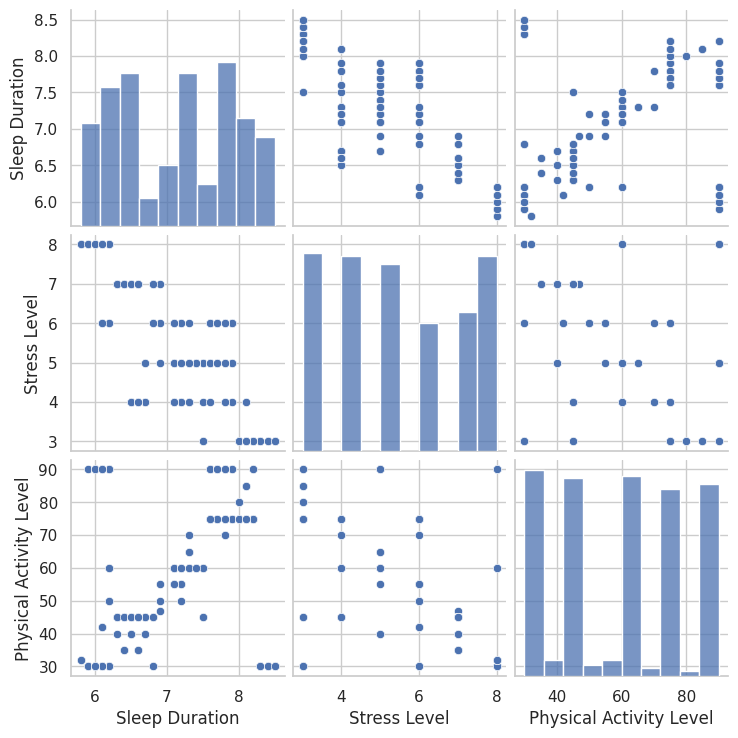

In [83]:
sns.pairplot(df[['Sleep Duration','Stress Level','Physical Activity Level']])

Scatterplot

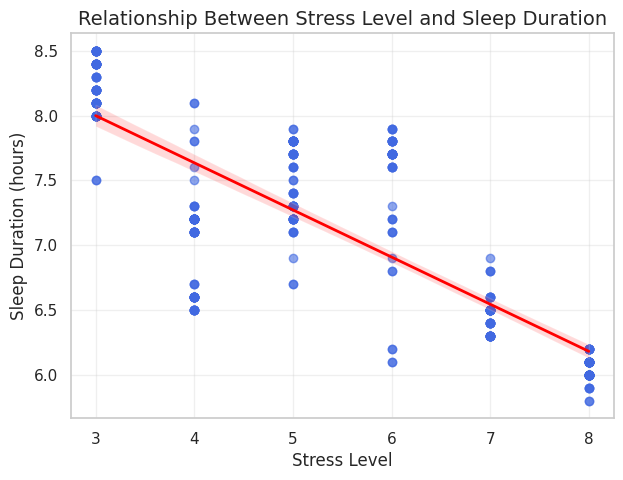

In [84]:
plt.figure(figsize=(7,5))
sns.set(style="whitegrid")

sns.regplot(data=df, x="Stress Level", y="Sleep Duration",
    scatter_kws={'alpha':0.6, 'color':'royalblue'},line_kws={'color':'red', 'linewidth':2})

plt.title("Relationship Between Stress Level and Sleep Duration", fontsize=14)
plt.xlabel("Stress Level", fontsize=12)
plt.ylabel("Sleep Duration (hours)", fontsize=12)
plt.grid(alpha=0.3)

plt.show()


Correlation Heatmap

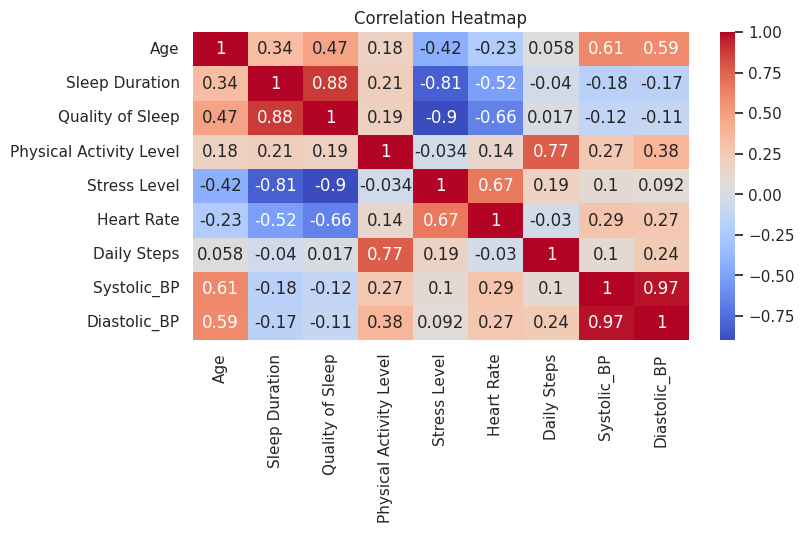

In [85]:
plt.figure(figsize=(8,4))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm')
plt.title("Correlation Heatmap")
plt.show()

### 7. Elbow Method

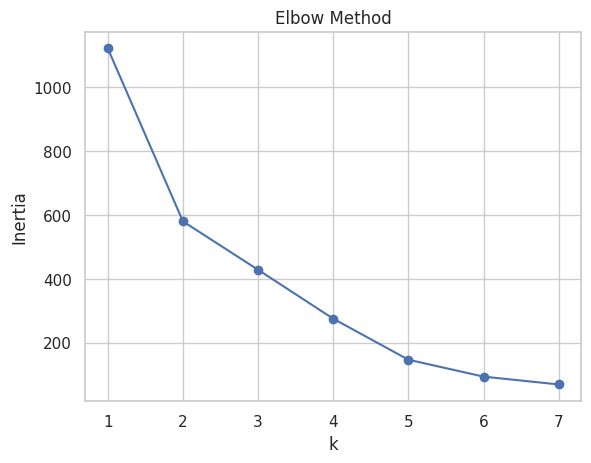

In [86]:
inertia = []
K = range(1, 8)

for k in K:
    km = KMeans(n_clusters=k, random_state=42).fit(scaled)
    inertia.append(km.inertia_)

plt.plot(K, inertia, 'o-')
plt.xlabel('k')
plt.ylabel('Inertia')
plt.title('Elbow Method')
plt.show()

### 8. K-Means Clustering

In [87]:
kmeans = KMeans(n_clusters=4, random_state=42)
df['Cluster'] = kmeans.fit_predict(scaled)

px.scatter(df, x='Sleep Duration', y='Stress Level', color=df['Cluster'],
           title="K-Means Cluster Visualization")

### 9. Silhouette Score

In [88]:
score = silhouette_score(scaled, df['Cluster'])
print(f"Silhouette Score: {score}")

Silhouette Score: 0.5707048574660717


### 10. Cluster Interpretation

In [89]:
# Cluster centroid values in original scale
centroids = kmeans.cluster_centers_
centroids_original = scaler.inverse_transform(centroids)

centroid_df = pd.DataFrame(centroids_original, columns=features.columns)
centroid_df

,Sleep Duration,Stress Level,Physical Activity Level
0,7.475829,4.502370,68.388626
1,6.065625,8.000000,90.000000
2,6.302062,7.278351,38.865979
3,8.370588,3.000000,30.882353


### 11. Cluster Profiles

In [90]:
cluster_summary = df.groupby('Cluster')[['Sleep Duration','Stress Level','Physical Activity Level','Heart Rate',
'Systolic_BP','Diastolic_BP','Daily Steps']].mean()
display(cluster_summary)

,Sleep Duration,Stress Level,Physical Activity Level,Heart Rate,Systolic_BP,Diastolic_BP,Daily Steps
Cluster,,,,,,,
0,7.475829,4.502370,68.388626,68.810427,127.578199,84.341232,7155.924171
1,6.065625,8.000000,90.000000,75.000000,140.000000,95.000000,10000.000000
2,6.302062,7.278351,38.865979,73.226804,128.247423,83.536082,5604.123711
3,8.370588,3.000000,30.882353,65.294118,124.705882,80.000000,5176.470588


Sleep Disorder count per cluster

In [91]:
pd.crosstab(df['Cluster'], df['Sleep Disorder'])

Sleep Disorder,Insomnia,No Disorder,Sleep Apnea
Cluster,,,
0,30,143,38
1,1,2,29
2,45,41,11
3,1,33,0


Average health metrics per cluster

In [92]:
df.groupby('Cluster')[['Age','Heart Rate','Daily Steps','Systolic_BP','Diastolic_BP']].mean()

,Age,Heart Rate,Daily Steps,Systolic_BP,Diastolic_BP
Cluster,,,,,
0,41.606635,68.810427,7155.924171,127.578199,84.341232
1,49.750000,75.000000,10000.000000,140.000000,95.000000
2,37.659794,73.226804,5604.123711,128.247423,83.536082
3,51.558824,65.294118,5176.470588,124.705882,80.000000


Boxplot Examples

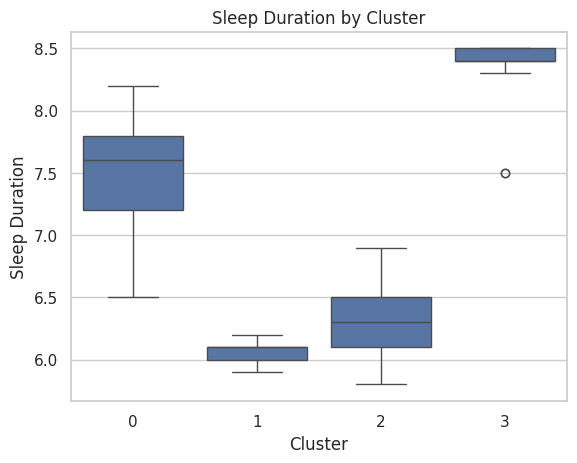

In [93]:
sns.boxplot(x='Cluster', y='Sleep Duration', data=df)
plt.title("Sleep Duration by Cluster")
plt.show()

In [94]:
# Final validation checks

print("Final dataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

print("\nCluster sizes:")
print(df["Cluster"].value_counts().sort_index())

print("\nSilhouette score:")
print(round(silhouette_score(scaled, df["Cluster"]), 3))

print("\nSleep disorder by cluster:")
print(pd.crosstab(
    df["Cluster"],
    df["Sleep Disorder"],
    normalize="index"
).round(3) * 100)

Final dataset shape: (374, 14)

Missing values:
Gender                     0
Age                        0
Occupation                 0
Sleep Duration             0
Quality of Sleep           0
Physical Activity Level    0
Stress Level               0
BMI Category               0
Heart Rate                 0
Daily Steps                0
Sleep Disorder             0
Systolic_BP                0
Diastolic_BP               0
Cluster                    0
dtype: int64

Cluster sizes:
Cluster
0    211
1     32
2     97
3     34
Name: count, dtype: int64

Silhouette score:
0.571

Sleep disorder by cluster:
Sleep Disorder  Insomnia  No Disorder  Sleep Apnea
Cluster                                           
0                   14.2         67.8         18.0
1                    3.1          6.2         90.6
2                   46.4         42.3         11.3
3                    2.9         97.1          0.0


### 12. Conclusion & Insights

## Key Findings
- The K-Means model identified four groups based on sleep duration, stress level, and physical activity level.
  - **Cluster 0: Longer Sleep and Moderate Stress.** Participants averaged approximately 7.48 hours of sleep, a stress level of 4.50, and a physical activity level of 68.39.
  - **Cluster 1: Shorter Sleep and High Stress.** Participants averaged approximately 6.07 hours of sleep, a stress level of 8.00, and a physical activity level of 90.00. Sleep Apnea was the most frequently recorded sleep-disorder category in this cluster.
  - **Cluster 2: Shorter Sleep, Higher Stress, and Lower Activity.** Participants averaged approximately 6.30 hours of sleep, a stress level of 7.28, and a physical activity level of 38.87. Insomnia was the most frequently recorded sleep-disorder category in this cluster.
- **Cluster 3: Longer Sleep and Low Stress.** Participants averaged approximately 8.37 hours of sleep, a stress level of 3.00, and a physical activity level of 30.88. Most participants in this cluster were recorded as having no sleep disorder.


### Model Evaluation

The four-cluster model achieved a silhouette score of approximately 0.571. This indicates reasonably distinct groupings overall, although some overlap between participants may remain.


### Interpretation

The clusters reveal different combinations of sleep duration, stress, and physical activity. Comparing sleep-disorder categories across these groups provides additional context about the participants represented in the dataset.

These findings describe patterns within this dataset. They do not establish that stress or physical activity causes a particular sleep disorder, and they should not be interpreted as medical conclusions.


### Limitations

- The analysis uses a limited set of three features for clustering.
- K-Means results can vary depending on feature selection, scaling, and the chosen number of clusters.
- Missing sleep-disorder labels require careful handling and should not automatically be treated as confirmed absence of a disorder.
- The results describe this dataset and may not generalize to other populations.


### Conclusion

This project demonstrates a structured data analytics workflow, from data cleaning and exploratory analysis to feature scaling, unsupervised machine learning, and cluster interpretation. It also demonstrates how analytical results can be communicated in a way that supports further investigation while acknowledging data limitations.

The project strengthened my practical experience with Python, Pandas, data visualization, and Scikit-learn, while connecting my investigative background to a data-driven approach to identifying and interpreting patterns.
